# Seminari 2 · Graph search

Kodi, raportet, figurat, animacioni dhe kontrollet janë në këtë notebook. Të dhënat lexohen nga `../data/shared/`. Përdor **Restart Kernel and Run All Cells** nga rrënja e projektit ose dosja `notebooks/`. Nuk kërkohen module lokale apo serverë. Dijkstra minimizon kilometrat; BFS minimizon dyert me kosto të barabartë. Gjurmët dhe rezultatet përdorin të njëjtët algoritme.

In [13]:
%matplotlib inline
import csv
import heapq
import json
import textwrap
from collections import deque
from dataclasses import dataclass, field
from io import StringIO
from math import isqrt
from pathlib import Path
from typing import NamedTuple

import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display
from IPython.utils.capture import capture_output
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def plural(n, word):
    return f"{n} {word}" if n == 1 else f"{n} {word}s"

# U1: Grafi ndërqytetas

Grafi përbëhet nga 8 qytete (nyje) dhe 9 rrugë ndërqytetase (degë). Është i padrejtuar, sepse çdo rrugë kalohet në të dy drejtimet, dhe i peshuar, sepse çdo degë ka si peshë distancën në kilometra. Distancat janë të përafërta dhe janë marrë nga planifikuesit publikë të rrugëve (distancë me makinë).

Për ta kaluar grafin në sistemin kompjuterik kemi zgjedhur **listën e fqinjësisë**: çdo qytet lidhet me fqinjët e tij dhe distancën deri tek ata (fjalor qytet → {fqinj: km}). Kjo formë është e përshtatshme sepse grafi është i rrallë, me 9 degë nga 28 çifte të mundshme, ndaj lista ruan vetëm rrugët që ekzistojnë dhe nuk harxhon vend si matrica e fqinjësisë. Ajo lexohet lehtë nga programi, përshkohet shpejt (BFS, DFS, Dijkstra) dhe shtimi i një qyteti të ri kërkon vetëm një hyrje të re. Çdo rrugë ruhet në të dy drejtimet me të njëjtën peshë.

Grafi është i lidhur (nga çdo qytet mund të arrihet në çdo tjetër) dhe ka dy cikle (Tiranë–Lezhë–Durrës dhe Tiranë–Durrës–Fier–Elbasan), prandaj ka rrugë alternative midis disa qyteteve.


# U2: Labirinti me 25 dhoma

Labirinti modelohet si graf: dhomat janë nyjet (25 gjithsej, të numëruara 1–25) dhe dyert midis dhomave janë degët (31 gjithsej). Grafi është i padrejtuar, sepse një derë hapet në të dy drejtimet, dhe i papeshuar, sepse detyra nuk jep distanca. Dhomat janë vendosur në një rrjetë 5×5 dhe vetëm dhomat ngjitur mund të kenë derë mes tyre.

Për ta kaluar në sistemin AI kemi zgjedhur **listën e fqinjësisë**: çdo dhomë lidhet me listën e dhomave ngjitur nëpërmjet dyerve (fjalor dhomë → [fqinjët]). Kjo formë ruan vetëm dyert që ekzistojnë, lexohet lehtë nga programi dhe është e përshtatshme për kërkim në graf (BFS, DFS) për të gjetur rrugën nga hyrja te dalja. Çdo derë ruhet në të dyja dhomat.

Kufizimet e detyrës janë kontrolluar në kod:
- Ka saktësisht 25 dhoma.
- Çdo dhomë ka minimalisht 2 dhe maksimalisht 4 porta. Në labirint kemi 16 dhoma me 2 porta, 6 me 3 porta dhe 3 me 4 porta. Meqë çdo dhomë ka të paktën 2 porta, labirinti nuk ka dhoma pa rrugëdalje, por ka unaza.
- Ka një hyrje (dhoma 1) dhe një dalje (dhoma 25). Hyrja dhe dalja janë dyer për jashtë dhe ruhen si dhoma të veçanta, jo si degë, ndaj nuk numërohen në 2–4 portat e dhomës.
- Grafi është i lidhur, pra dalja arrihet nga hyrja. Rruga më e shkurtër ka 12 dyer.


In [14]:
def find_data_dir(start=None):
    """Find data/ from the repository root or the notebooks directory."""
    start = Path.cwd() if start is None else Path(start)
    start = start.resolve()
    for directory in (start, *start.parents):
        if (directory / "data").is_dir():
            return directory / "data"
    raise FileNotFoundError("Cannot find data/. Keep it alongside notebooks/ and launch from the project.")

DATA_DIR = find_data_dir()

CITIES_CSV = (DATA_DIR / "shared/cities.csv").read_text(encoding="utf-8-sig")
DOORS_CSV = (DATA_DIR / "shared/maze_doors.csv").read_text(encoding="utf-8-sig")
CONFIG_JSON = (DATA_DIR / "shared/maze_config.json").read_text(encoding="utf-8")
display(pd.read_csv(StringIO(CITIES_CSV)))

,city_a,city_b,km,quality
0,Shkodër,Lezhë,40,good
1,Lezhë,Tirana,62,highway
2,Lezhë,Durrës,70,fair
3,Tirana,Durrës,36,highway
4,Tirana,Elbasan,42,good
5,Durrës,Fier,81,good
6,Elbasan,Fier,77,fair
7,Fier,Vlorë,37,highway
8,Elbasan,Korçë,123,poor


## Algoritmet / Algorithms

Dijkstra përdor një heap me përparësi. BFS përdor radhë FIFO dhe fqinjë të renditur për rezultate deterministe. Gjeneratorët japin gjendjen pas çdo hapi.

In [15]:
def _rebuild(prev, goal):
    """Walk the prev links back from goal and return the path start -> goal."""
    path = [goal]
    while prev.get(path[-1]) is not None:
        path.append(prev[path[-1]])
    return path[::-1]


def _event(kind, message, frontier, visited, dist, prev, **fields):
    """One trace step: a plain dict with fresh copies of the search state."""
    return {
        "type": kind,
        "message": message,
        **fields,
        "frontier": frontier,
        "visited": list(visited),
        "dist": dict(dist),
        "prev": dict(prev),
    }


def dijkstra_steps(edges, start, goal, unit="km"):
    """Dijkstra as a generator of JSON-serialisable step events.

    Types: start, pop, skip, relax, found (last), fail (last). Every event also
    has frontier (sorted [cost, node] heap contents), visited, dist and prev.
    """
    dist = {start: 0}
    prev = {start: None}
    visited = []
    heap = [(0, start)]

    def snap():
        return [list(item) for item in sorted(heap)]

    yield _event("start", f"Start at {start} with cost 0 {unit}; it is the only node on the frontier.",
                 snap(), visited, dist, prev, node=start)
    while heap:
        d, node = heapq.heappop(heap)
        if node == goal:
            visited.append(node)
            yield _event("pop", f"Pop {node} ({d} {unit}), the goal.",
                         snap(), visited, dist, prev, node=node, cost=d)
            path = _rebuild(prev, goal)
            yield _event("found", f"Goal reached: {' → '.join(map(str, path))} costs {d} {unit}.",
                         snap(), visited, dist, prev, path=path, cost=d)
            return
        if d > dist.get(node, float("inf")):
            yield _event("skip", f"Pop {node} ({d} {unit}), but a cheaper route ({dist[node]} {unit}) "
                                 "is already known, so this entry is stale; skip it.",
                         snap(), visited, dist, prev, node=node, cost=d)
            continue
        visited.append(node)
        yield _event("pop", f"Pop {node} ({d} {unit}), the cheapest node on the frontier.",
                     snap(), visited, dist, prev, node=node, cost=d)
        for nxt, cost in edges(node):
            nd = d + cost
            old = dist.get(nxt)
            improved = old is None or nd < old
            if improved:
                dist[nxt] = nd
                prev[nxt] = node
                heapq.heappush(heap, (nd, nxt))
                message = (f"Relax {node}→{nxt}: {d} + {cost} = {nd} {unit} is better than "
                           f"{'∞' if old is None else f'{old} {unit}'}, update.")
            else:
                message = (f"Relax {node}→{nxt}: {d} + {cost} = {nd} {unit} is not better than "
                           f"{old} {unit}, keep the old value.")
            yield _event("relax", message, snap(), visited, dist, prev,
                         **{"from": node, "to": nxt, "edge": cost, "new_cost": nd,
                            "old_cost": old, "improved": improved})
    yield _event("fail", f"The frontier is empty and {goal} was never reached: no route exists.",
                 [], visited, dist, prev)


def bfs_steps(edges, start, goal):
    """BFS as a generator of JSON-serialisable step events.

    Types: start, pop, discover, found (last), fail (last). dist is the depth in
    edges; frontier is the queue as a list of nodes.
    """
    prev = {start: None}
    dist = {start: 0}
    visited = []
    queue = deque([start])
    yield _event("start", f"Start at {start} ({plural(0, 'door')}); it is the only node in the queue.",
                 list(queue), visited, dist, prev, node=start)
    while queue:
        node = queue.popleft()
        visited.append(node)
        if node == goal:
            yield _event("pop", f"Take {node} ({plural(dist[node], 'door')}) from the queue, the goal.",
                         list(queue), visited, dist, prev, node=node, cost=dist[node])
            path = _rebuild(prev, goal)
            yield _event("found", f"Goal reached: {' → '.join(map(str, path))} in {plural(dist[node], 'door')}.",
                         list(queue), visited, dist, prev, path=path, cost=dist[node])
            return
        yield _event("pop", f"Take {node} ({plural(dist[node], 'door')}) from the front of the queue.",
                     list(queue), visited, dist, prev, node=node, cost=dist[node])
        for nxt, _ in edges(node):
            new = nxt not in prev
            if new:
                prev[nxt] = node
                dist[nxt] = dist[node] + 1
                queue.append(nxt)
                message = f"Discover {nxt} from {node}: new, {plural(dist[nxt], 'door')}; add it to the queue."
            else:
                message = f"Look at {nxt} from {node}: already seen, ignore it."
            yield _event("discover", message, list(queue), visited, dist, prev,
                         **{"from": node, "to": nxt, "new": new})
    yield _event("fail", f"The queue is empty and {goal} was never reached: no path exists.",
                 [], visited, dist, prev)


def dijkstra(edges, start, goal):
    """Cheapest path by total cost. Returns (path, cost) or (None, None)."""
    for event in dijkstra_steps(edges, start, goal):
        if event["type"] == "found":
            return event["path"], event["cost"]
    return None, None


def bfs(edges, start, goal):
    """Path with the fewest edges (costs ignored). Returns the path or None.

    Ties are broken by the order in which `edges` yields neighbours.
    """
    for event in bfs_steps(edges, start, goal):
        if event["type"] == "found":
            return event["path"]
    return None


def build_steps(adjacency, weighted, unit="km"):
    """Trace reading an adjacency mapping into a graph, in insertion order.

    Yields add_node (node) and add_edge (a, b, cost) once per undirected edge.
    Weighted costs are copied from the adjacency; unweighted edges cost 1.
    A weighted add_edge message names `unit` ("km", "cost", ...). Every event
    carries the nodes and edges counts so far.
    """
    seen_nodes = []
    seen_edges = set()
    count = {"nodes": 0, "edges": 0}

    def node_event(node):
        seen_nodes.append(node)
        count["nodes"] += 1
        return {"type": "add_node", "message": f"Add node {node} to the graph.",
                "node": node, **count}

    for a, neighbours in adjacency.items():
        items = neighbours.items() if weighted else ((n, 1) for n in neighbours)
        for b, cost in items:
            key = frozenset((a, b))
            if key in seen_edges:
                continue
            for n in (a, b):
                if n not in seen_nodes:
                    yield node_event(n)
            seen_edges.add(key)
            count["edges"] += 1
            if weighted:
                message = f"Read road {a}–{b} ({cost} {unit}); store it in both directions."
            else:
                message = f"Read door {a}–{b}; rooms {a} and {b} become neighbours."
            yield {"type": "add_edge", "message": message, "a": a, "b": b,
                   "cost": cost, **count}
    for n in adjacency:
        if n not in seen_nodes:
            yield node_event(n)


class Graph:
    """Undirected graph over an adjacency mapping.

    weighted=True:  adjacency is {node: {neighbour: cost}}.
    weighted=False: adjacency is {node: [neighbours]}, every edge costs 1.
    """

    def __init__(self, adjacency, weighted):
        self.adjacency = adjacency
        self.weighted = weighted

    def edges(self, node):
        """(neighbour, cost) pairs; unweighted neighbours come out sorted."""
        if self.weighted:
            return self.adjacency[node].items()
        return ((n, 1) for n in sorted(self.adjacency[node]))

    def shortest_path(self, start, goal):
        """(path, cost) or (None, None): Dijkstra if weighted, else BFS.

        An unknown start or goal gives (None, None).
        """
        if start not in self.adjacency or goal not in self.adjacency:
            return None, None
        if self.weighted:
            return dijkstra(self.edges, start, goal)
        path = bfs(self.edges, start, goal)
        return (path, len(path) - 1) if path else (None, None)

    def build_steps(self, unit="km"):
        """Trace of building this graph; see module-level build_steps."""
        return build_steps(self.adjacency, self.weighted, unit)

    def search_steps(self, start, goal, unit="km"):
        """Step events of Dijkstra (weighted) or BFS; unknown node -> one fail."""
        for name, node in (("start", start), ("goal", goal)):
            if node not in self.adjacency:
                yield _event("fail", f"Unknown {name} node {node}: it is not in the graph.",
                             [], [], {}, {})
                return
        if self.weighted:
            yield from dijkstra_steps(self.edges, start, goal, unit)
        else:
            yield from bfs_steps(self.edges, start, goal)

    def is_connected(self):
        """True if every node can be reached from any other (False if empty)."""
        if not self.adjacency:
            return False
        start = next(iter(self.adjacency))
        seen, stack = {start}, [start]
        while stack:
            for nxt, _ in self.edges(stack.pop()):
                if nxt not in seen:
                    seen.add(nxt)
                    stack.append(nxt)
        return len(seen) == len(self.adjacency)

    def __contains__(self, node):
        return node in self.adjacency

    def __len__(self):
        return len(self.adjacency)

    def __iter__(self):
        return iter(self.adjacency)

## Validimi i të dhënave / Dataset validation

CSV-të dhe konfigurimi JSON lexohen nga `../data/shared/`. Ngarkuesit validojnë përmbajtjen para ndërtimit të grafeve. Ndrysho skedarët për eksperimente; të dhënat e pavlefshme refuzohen. Kontrollet përdorin edhe shembuj të vegjël në memorie për hyrjet e gabuara.

In [16]:
DEFAULT_PATH = CITIES_CSV
QUALITIES = ("highway", "good", "fair", "poor")  # best to worst


def _city_is_blank(row):
    """True if every cell of a csv.DictReader row is empty or whitespace."""
    cells = []
    for v in row.values():
        cells.extend(v if isinstance(v, list) else [v])
    return all(c is None or not c.strip() for c in cells)


def load_graph(path=DEFAULT_PATH):
    """Read the roads from a CSV file and build the symmetric adjacency dict.

    File format: header city_a,city_b,km, then one row per road (each road once).
    Raises ValueError if the data is malformed or the graph is not connected.
    """
    with StringIO(path.lstrip("\ufeff")) as f:
        reader = csv.DictReader(f)
        missing = {"city_a", "city_b", "km"} - set(reader.fieldnames or [])
        if missing:
            raise ValueError(f"{path}: missing column(s) {sorted(missing)}")
        rows = [(reader.line_num, row) for row in reader]   # csv skips blank lines, so enumerate would drift
    if not rows:
        raise ValueError(f"{path}: no roads found")

    g = {}
    seen = set()
    for line, row in rows:
        if _city_is_blank(row):
            continue
        a, b, raw_km = (row["city_a"] or "").strip(), (row["city_b"] or "").strip(), row["km"]
        if not a or not b or raw_km is None or None in row:
            raise ValueError(f"{path} line {line}: expected 3 values city_a,city_b,km")
        try:
            km = int(raw_km)
        except ValueError:
            raise ValueError(f"{path} line {line}: km must be an integer, got {raw_km!r}") from None
        if km <= 0:
            raise ValueError(f"road {a}-{b} has a non-positive distance: {km}")
        if a == b:
            raise ValueError(f"road {a}-{b} joins a city to itself")
        if frozenset((a, b)) in seen:
            raise ValueError(f"duplicate road {a}-{b}")
        seen.add(frozenset((a, b)))
        g.setdefault(a, {})[b] = km
        g.setdefault(b, {})[a] = km

    if not g:
        raise ValueError(f"{path}: no roads found")
    if not city_is_connected(g):
        raise ValueError("the road network is not connected")
    return g


def load_roads(path=DEFAULT_PATH):
    """Read the road quality: {city: {neighbour: quality}}, both directions.

    Needs the 4th column `quality` (one of QUALITIES). The rest of the file is
    validated by load_graph. Raises ValueError with path and line number.
    """
    load_graph(path)
    with StringIO(path.lstrip("\ufeff")) as f:
        reader = csv.DictReader(f)
        if "quality" not in (reader.fieldnames or []):
            raise ValueError(f"{path}: missing column(s) ['quality']")
        rows = [(reader.line_num, row) for row in reader]   # csv skips blank lines, so enumerate would drift

    roads = {}
    for line, row in rows:
        if _city_is_blank(row):
            continue
        a, b = row["city_a"].strip(), row["city_b"].strip()
        quality = (row["quality"] or "").strip()
        if quality not in QUALITIES:
            raise ValueError(f"{path} line {line}: quality must be one of "
                             f"{', '.join(QUALITIES)}, got {quality!r}")
        roads.setdefault(a, {})[b] = quality
        roads.setdefault(b, {})[a] = quality
    return roads


def city_is_symmetric(g):
    """Every road must be stored in both directions with the same weight."""
    return all(b in g and g[b].get(a) == w for a in g for b, w in g[a].items())


def city_is_connected(g):
    """True if every city can be reached from any other city."""
    return Graph(g, weighted=True).is_connected()


def edge_list(g):
    """Each road once, as (city_a, city_b, km), sorted by city_a then city_b."""
    return sorted(
        (a, b, km) for a, roads in g.items() for b, km in roads.items() if a < b
    )


def edge_table(g):
    """Markdown table of all roads, for the report."""
    rows = ["| # | City A | City B | Distance (km) |", "|---|---|---|---|"]
    for i, (a, b, km) in enumerate(edge_list(g), start=1):
        rows.append(f"| {i} | {a} | {b} | {km} |")
    return "\n".join(rows)

In [17]:
DEFAULT_DOORS_PATH = DOORS_CSV
DEFAULT_CONFIG_PATH = CONFIG_JSON

MIN_DOORS = 2
MAX_DOORS = 4

# Rooms are numbered 1..rooms, row by row, on a square grid whose width is
# isqrt(rooms) (5x5 for 25 rooms):
#    1  2  3  4  5
#    6  7  8  9 10
#   11 12 13 14 15
#   16 17 18 19 20
#   21 22 23 24 25
# Only rooms next to each other can share a door. Every room needs at least
# 2 doors, so the maze has loops and no dead ends.


class Maze(NamedTuple):
    rooms: int
    entrance: int
    exit: int
    doors: list
    adjacency: dict


def grid_width(rooms):
    """Width of the square grid; the room count must be a perfect square."""
    width = isqrt(rooms) if isinstance(rooms, int) and rooms > 0 else 0
    if width * width != rooms:
        raise ValueError(f"room count must be a positive perfect square, got {rooms!r}")
    return width


def build_maze(doors, rooms):
    """Adjacency list from the door list; each door is stored in both rooms."""
    if len({frozenset(d) for d in doors}) != len(doors):
        raise ValueError("duplicate door in the door list")
    g = {room: [] for room in range(1, rooms + 1)}
    for a, b in doors:
        for room in (a, b):
            if room not in g:
                raise ValueError(f"door {a}-{b} uses room {room}, which does not exist")
        g[a].append(b)
        g[b].append(a)
    return g


def is_symmetric(g):
    """Every door must be stored in both rooms."""
    return all(b in g and a in g[b] for a in g for b in g[a])


def is_connected(g):
    """True if every room can be reached from any other room."""
    return Graph(g, weighted=False).is_connected()


def is_grid_neighbour(a, b, width):
    """True if rooms a and b are next to each other on the grid."""
    (ra, ca), (rb, cb) = divmod(a - 1, width), divmod(b - 1, width)
    return abs(ra - rb) + abs(ca - cb) == 1


def validate(g, entrance, exit_, rooms):
    """Return a list of broken rules (empty list means the maze is valid)."""
    errors = []
    if set(g) != set(range(1, rooms + 1)):
        errors.append(f"rooms must be exactly the numbers 1-{rooms}")
        return errors
    width = grid_width(rooms)
    for room, doors in g.items():
        if any(d not in g for d in doors):
            errors.append(f"room {room} has a door to a room that does not exist")
            return errors
    for room, doors in g.items():
        if len(set(doors)) != len(doors):
            errors.append(f"room {room} lists the same door twice")
        if not MIN_DOORS <= len(doors) <= MAX_DOORS:
            errors.append(f"room {room} has {len(doors)} doors")
        if room in doors:
            errors.append(f"room {room} has a door to itself")
        for other in doors:
            if not is_grid_neighbour(room, other, width):
                errors.append(f"door {room}-{other} joins rooms that are not neighbours")
    if not is_symmetric(g):
        errors.append("a door is not stored in both rooms")
    if entrance not in g or exit_ not in g:
        errors.append("entrance or exit is not a room")
    elif entrance == exit_:
        errors.append("entrance and exit are the same room")
    if not is_connected(g):
        errors.append("maze is not connected")
    return errors


def _is_blank(row):
    """True if every cell of a csv.DictReader row is empty or whitespace."""
    cells = []
    for v in row.values():
        cells.extend(v if isinstance(v, list) else [v])
    return all(c is None or not c.strip() for c in cells)


def _int(path, line, what, raw):
    try:
        return int(raw)
    except (TypeError, ValueError):
        raise ValueError(f"{path} line {line}: {what} must be an integer, got {raw!r}") from None


def parse_maze_config(text):
    """Validate JSON maze settings before constructing the graph."""
    config = json.loads(text)
    required = {"rooms", "entrance", "exit"}
    if not isinstance(config, dict) or not required <= config.keys():
        raise ValueError("maze_config.json: expected rooms, entrance and exit")
    if any(type(config[key]) is not int for key in required):
        raise ValueError("maze_config.json: settings must be integers")
    rooms = config["rooms"]
    if rooms <= 0 or isqrt(rooms) ** 2 != rooms:
        raise ValueError("maze_config.json: rooms must be a positive perfect square")
    if not 1 <= config["entrance"] <= rooms or not 1 <= config["exit"] <= rooms:
        raise ValueError("maze_config.json: entrance and exit must be existing rooms")
    if config["entrance"] == config["exit"]:
        raise ValueError("maze_config.json: entrance and exit must be different")
    return config


def _read_config(path):
    return parse_maze_config(path)


def _read_doors(path):
    """Read the room_a,room_b file into a list of (a, b) tuples."""
    with StringIO(path.lstrip("\ufeff")) as f:
        reader = csv.DictReader(f)
        missing = {"room_a", "room_b"} - set(reader.fieldnames or [])
        if missing:
            raise ValueError(f"{path}: missing column(s) {sorted(missing)}")
        doors = []
        for row in reader:
            line = reader.line_num   # csv skips blank lines, so enumerate would drift
            if _is_blank(row):
                continue
            if None in row or row["room_b"] is None:
                raise ValueError(f"{path} line {line}: expected 2 values room_a,room_b")
            doors.append((_int(path, line, "room_a", row["room_a"]),
                          _int(path, line, "room_b", row["room_b"])))
    return doors


def load_maze(doors_path=DEFAULT_DOORS_PATH, config_path=DEFAULT_CONFIG_PATH):
    """Read the maze from two CSV files, validate it and return a Maze.

    Config JSON: integer rooms, entrance and exit.
    Doors file: header room_a,room_b, one row per door.
    Raises ValueError on malformed rows or listing the broken rules if invalid.
    """
    config = _read_config(config_path)
    rooms, entrance, exit_ = config["rooms"], config["entrance"], config["exit"]
    doors = _read_doors(doors_path)
    grid_width(rooms)
    adjacency = build_maze(doors, rooms)
    problems = validate(adjacency, entrance, exit_, rooms)
    if problems:
        raise ValueError("invalid maze: " + "; ".join(problems))
    return Maze(rooms, entrance, exit_, doors, adjacency)


def door_table(doors):
    """Markdown table of all doors, for the report."""
    rows = ["| # | Room A | Room B |", "|---|---|---|"]
    for i, (a, b) in enumerate(sorted(doors), start=1):
        rows.append(f"| {i} | {a} | {b} |")
    return "\n".join(rows)

In [18]:
QUALITY_FACTOR = {"highway": 1.0, "good": 1.3, "fair": 1.8, "poor": 2.5}


def road_cost(km, quality):
    """Cost of one road; rounded so float noise (62 * 1.3) stays out of the output."""
    return round(km * QUALITY_FACTOR[quality], 1)


def cost_adjacency(graph, roads):
    """{city: {neighbour: cost}} from the km graph and the quality map."""
    return {a: {b: road_cost(km, roads[a][b]) for b, km in nbs.items()}
            for a, nbs in graph.items()}


def best_quality_route(graph, roads, start, goal):
    """Cheapest route by quality-weighted cost.

    Returns {"route", "total_km", "quality_cost", "legs", "worst_road"} or None
    if there is no route. legs is [{from, to, km, quality}]; worst_road is the
    worst quality on the route ("highway" for a zero-length route).
    """
    path, cost = Graph(cost_adjacency(graph, roads), weighted=True).shortest_path(start, goal)
    if path is None:
        return None
    legs = [{"from": a, "to": b, "km": graph[a][b], "quality": roads[a][b]}
            for a, b in zip(path, path[1:], strict=False)]
    worst = max((leg["quality"] for leg in legs), key=QUALITIES.index, default=QUALITIES[0])
    return {"route": path, "total_km": sum(leg["km"] for leg in legs),
            "quality_cost": round(cost, 1), "legs": legs, "worst_road": worst}

## Rezultatet / Results

Rruga Shkodër → Korçë ka 267 km; kostoja e ponderuar nga cilësia është 476.1, jo kilometra. Faktorët janë highway 1.0, good 1.3, fair 1.8 dhe poor 2.5. Labirinti ka rrugë me 12 dyer.

In [19]:
cities, qualities, maze = load_graph(), load_roads(), load_maze()
city_search, maze_search = Graph(cities, True), Graph(maze.adjacency, False)
city_path, city_cost = city_search.shortest_path("Shkodër", "Korçë")
maze_path, maze_cost = maze_search.shortest_path(1, 25)
print("Cities:", city_path, city_cost, "km")
print("Quality:", best_quality_route(cities, qualities, "Shkodër", "Korçë"))
print("Maze:", maze_path, maze_cost, "doors")
display(pd.DataFrame(list(city_search.search_steps("Shkodër", "Korçë")))[["type", "message"]])

Cities: ['Shkodër', 'Lezhë', 'Tirana', 'Elbasan', 'Korçë'] 267 km
Quality: {'route': ['Shkodër', 'Lezhë', 'Tirana', 'Elbasan', 'Korçë'], 'total_km': 267, 'quality_cost': 476.1, 'legs': [{'from': 'Shkodër', 'to': 'Lezhë', 'km': 40, 'quality': 'good'}, {'from': 'Lezhë', 'to': 'Tirana', 'km': 62, 'quality': 'highway'}, {'from': 'Tirana', 'to': 'Elbasan', 'km': 42, 'quality': 'good'}, {'from': 'Elbasan', 'to': 'Korçë', 'km': 123, 'quality': 'poor'}], 'worst_road': 'poor'}
Maze: [1, 2, 3, 8, 13, 18, 17, 16, 21, 22, 23, 24, 25] 12 doors


,type,message
0,start,Start at Shkodër with cost 0 km; it is the onl...
1,pop,"Pop Shkodër (0 km), the cheapest node on the f..."
2,relax,Relax Shkodër→Lezhë: 0 + 40 = 40 km is better ...
3,pop,"Pop Lezhë (40 km), the cheapest node on the fr..."
4,relax,Relax Lezhë→Shkodër: 40 + 40 = 80 km is not be...
5,relax,Relax Lezhë→Tirana: 40 + 62 = 102 km is better...
6,relax,Relax Lezhë→Durrës: 40 + 70 = 110 km is better...
7,pop,"Pop Tirana (102 km), the cheapest node on the ..."
8,relax,Relax Tirana→Lezhë: 102 + 62 = 164 km is not b...
9,relax,Relax Tirana→Durrës: 102 + 36 = 138 km is not ...


## Figura, gjurmë dhe animacione / Inline views

Të njëjtat ngjarje ndërtojnë figurat dhe animacionet. Animacioni krijohet vetëm kur zgjidhet nga kontrollet më poshtë.

In [20]:
# Hand-placed (x, y) positions, roughly following the real map.
CITY_POS = {
    "Shkodër": (0.0, 5.0),
    "Lezhë":   (1.0, 3.6),
    "Tirana":  (3.0, 3.0),
    "Durrës":  (1.6, 2.0),
    "Elbasan": (4.4, 1.8),
    "Fier":    (2.2, 0.4),
    "Vlorë":   (1.0, -0.8),
    "Korçë":   (6.4, 0.6),
}


def maze_position(room, width):
    """Room 1 is top left; rooms are numbered row by row. Returns (col, -row)."""
    row, col = divmod(room - 1, width)
    return col, -row

In [21]:
INF = "∞"
HOLD_SECONDS = 2.5

# Node fill colours by role.
IDLE = "#8fbce6"
FRONTIER = "#ffd92f"
VISITED = "#4c6a92"
CURRENT = "#ff7f0e"
START_COLOR = "#2ca02c"
GOAL_COLOR = "#d62728"
PATH_COLOR = "#d81b60"
IMPROVED = "#2ca02c"
NOT_IMPROVED = "#999999"
EDGE = "#555555"
LABEL_COLOR = "#b00020"


@dataclass
class Scene:
    """What differs between the two problems."""

    adjacency: dict
    weighted: bool
    pos: dict
    start: object
    goal: object
    title: str                      # graph title during phase 1
    algorithm: str                  # "Dijkstra" or "BFS"
    unit: str                       # "km" or "doors"
    start_label: str = "Start"
    goal_label: str = "Goal"
    node_size: int = 1700
    font_size: float = 8
    color_endpoints: bool = False   # maze: entrance green / exit red fill in phase 1
    figsize: tuple = (12, 6.5)
    hold: int = 0
    frames: list = field(default_factory=list)


def _frame(**fields):
    base = {"phase": 1, "kind": "", "heading": "", "title": "", "message": "",
            "nodes": [], "edges": [], "roles": {}, "highlight": None, "path": None,
            "frontier": None, "dist": None, "prev": None, "counts": None}
    base.update(fields)
    return base


def _edge_key(a, b):
    return frozenset((a, b))


def build_frames(scene, hold=0):
    """Frame dicts: one per build event, one per search event, then `hold` copies of the last."""
    graph = Graph(scene.adjacency, scene.weighted)
    frames = []
    nodes, edges = [], []
    for ev in graph.build_steps(scene.unit):
        if ev["type"] == "add_node":
            nodes = nodes + [ev["node"]]
        else:
            edges = edges + [(ev["a"], ev["b"], ev["cost"])]
        frames.append(_frame(
            phase=1, kind=ev["type"], heading="1. Building the graph from the CSV",
            title=scene.title, message=ev["message"], nodes=nodes, edges=edges,
            counts=(ev["nodes"], ev["edges"]),
        ))

    all_nodes = list(nodes)
    all_edges = list(edges)
    heading = f"2. {scene.algorithm} search"
    for ev in graph.search_steps(scene.start, scene.goal):
        kind = ev["type"]
        visited = list(ev["visited"])
        if scene.weighted:
            queue = [node for _, node in ev["frontier"]]
            frontier_lines = [f"{node} ({cost} {scene.unit})" for cost, node in ev["frontier"]]
        else:
            queue = list(ev["frontier"])
            frontier_lines = [str(node) for node in queue]
        current = None
        highlight = None
        path = None
        title = f"{scene.algorithm}: {scene.start} → {scene.goal}"
        if kind in ("start", "pop", "skip"):
            current = ev["node"]
        elif kind in ("relax", "discover"):
            current = ev["from"]
            good = ev["improved"] if kind == "relax" else ev["new"]
            highlight = (ev["from"], ev["to"], "good" if good else "bad")
        elif kind == "found":
            path = ev["path"]
            cost = f"{ev['cost']} km" if scene.weighted else plural(ev["cost"], "door")
            title = (f"Shortest {'route' if scene.weighted else 'path'} {scene.start} → "
                     f"{scene.goal}: {cost}")
        elif kind == "fail":
            title = f"No path from {scene.start} to {scene.goal}"
        roles = {}
        for node in queue:
            roles[node] = "frontier"
        for node in visited:
            roles[node] = "visited"
        if current is not None:
            roles[current] = "current"
        frames.append(_frame(
            phase=2, kind=kind, heading=heading, title=title, message=ev["message"],
            nodes=all_nodes, edges=all_edges, roles=roles, highlight=highlight, path=path,
            frontier=frontier_lines, dist=dict(ev["dist"]), prev=dict(ev["prev"]),
        ))
    frames.extend([frames[-1]] * hold)
    return frames


def hold_frames(fps):
    return round(HOLD_SECONDS * fps)


def _table_lines(scene, frame):
    """Monospace dist/prev table: one column for few nodes, three for many."""
    order = list(scene.adjacency)
    cells = []
    for node in order:
        d = frame["dist"].get(node)
        p = frame["prev"].get(node)
        dist = INF if d is None else str(d)
        parent = "–" if p is None else str(p)
        if scene.weighted:
            cells.append(f"{node!s:<8}{dist:>5}  ← {parent}")
        else:
            cells.append(f"{node!s:>2} {dist:>2} ←{parent:>2}")
    ncols = 1 if len(order) <= 10 else 3
    rows = -(-len(cells) // ncols)
    gap = "   "
    lines = []
    for r in range(rows):
        lines.append(gap.join(cells[r + c * rows] for c in range(ncols) if r + c * rows < len(cells)))
    header = "Node      km  ← prev" if scene.weighted else "Rm dr ←prv"
    if ncols > 1:
        header = gap.join([header] * ncols)
    return [header] + lines


def _draw_graph(ax, scene, frame):
    ax.clear()
    ax.set_aspect("equal")
    xs = [p[0] for p in scene.pos.values()]
    ys = [p[1] for p in scene.pos.values()]
    ax.set_xlim(min(xs) - 0.8, max(xs) + 0.8)
    ax.set_ylim(min(ys) - 0.8, max(ys) + 0.8)
    ax.axis("off")
    ax.set_title(frame["title"], fontsize=12, fontweight="bold")

    path_edges = set()
    if frame["path"]:
        path_edges = {_edge_key(a, b) for a, b in zip(frame["path"], frame["path"][1:], strict=False)}
    hl = frame["highlight"]
    hl_key = _edge_key(hl[0], hl[1]) if hl else None

    for a, b, cost in frame["edges"]:
        (x1, y1), (x2, y2) = scene.pos[a], scene.pos[b]
        key = _edge_key(a, b)
        color, width, style, z = EDGE, 2, "-", 1
        if key in path_edges:
            color, width, z = PATH_COLOR, 6, 1.5
        elif key == hl_key:
            color = IMPROVED if hl[2] == "good" else NOT_IMPROVED
            width, z = 5, 1.5
            style = "-" if hl[2] == "good" else (0, (3, 2))
        ax.plot([x1, x2], [y1, y2], color=color, linewidth=width, linestyle=style, zorder=z)
        if scene.weighted:
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, f"{cost} km", ha="center", va="center",
                    fontsize=9, color=LABEL_COLOR, zorder=3,
                    bbox={"boxstyle": "round,pad=0.2", "fc": "white", "ec": "none"})

    for node in frame["nodes"]:
        x, y = scene.pos[node]
        role = frame["roles"].get(node)
        fill = {"current": CURRENT, "frontier": FRONTIER, "visited": VISITED}.get(role, IDLE)
        text = "white" if role == "visited" else "black"
        ring, ring_w = "black", 1
        if frame["phase"] == 1 and scene.color_endpoints and node in (scene.start, scene.goal):
            fill = START_COLOR if node == scene.start else GOAL_COLOR
            text = "white"
        if frame["phase"] == 2 and node == scene.start:
            ring, ring_w = START_COLOR, 4
        elif frame["phase"] == 2 and node == scene.goal:
            ring, ring_w = GOAL_COLOR, 4
        ax.scatter(x, y, s=scene.node_size, color=fill, edgecolor=ring, linewidths=ring_w, zorder=2)
        ax.text(x, y, str(node), ha="center", va="center", fontsize=scene.font_size,
                fontweight="bold", color=text, zorder=4)
        if frame["phase"] == 2 and node in (scene.start, scene.goal):
            label, color = ((scene.start_label, START_COLOR) if node == scene.start
                            else (scene.goal_label, GOAL_COLOR))
            ax.text(x, y - 0.5, label, ha="center", va="top", fontsize=9,
                    fontweight="bold", color=color, zorder=4)


def _draw_panel(panel, scene, frame):
    panel.clear()
    panel.axis("off")
    panel.set_xlim(0, 1)
    panel.set_ylim(0, 1)
    height_pt = scene.figsize[1] * 72 * 0.86
    cursor = 0.99

    def put(lines, size, **kw):
        nonlocal cursor
        lines = list(lines)
        panel.text(0, cursor, "\n".join(lines), va="top", ha="left", fontsize=size, **kw)
        cursor -= len(lines) * size * 1.4 / height_pt + 0.025

    put([frame["heading"]], 13, fontweight="bold")
    put(textwrap.wrap(frame["message"], 46) or [""], 11)
    if frame["phase"] == 1:
        nodes, edges = frame["counts"]
        if scene.weighted:
            nodes_text = f"{nodes} {'city' if nodes == 1 else 'cities'}"
            edges_text = plural(edges, "road")
        else:
            nodes_text = plural(nodes, "room")
            edges_text = plural(edges, "door")
        put([f"{nodes_text}, {edges_text} so far"], 11, fontweight="bold")
        return
    queue_name = "priority queue, cheapest first" if scene.weighted else "FIFO queue, front first"
    put([f"Frontier ({queue_name}):"], 11, fontweight="bold")
    items = ", ".join(frame["frontier"]) if frame["frontier"] else "(empty)"
    put(textwrap.wrap(items, 46)[:4], 10.5)
    unit = scene.unit
    put([f"Distances ({unit}) and parents:"], 11, fontweight="bold")
    put(_table_lines(scene, frame), 9, family="monospace")
    handles = [
        Patch(fc=CURRENT, ec="black", label="current node"),
        Patch(fc=FRONTIER, ec="black", label="frontier"),
        Patch(fc=VISITED, ec="black", label="visited / settled"),
        Patch(fc=IDLE, ec="black", label="not seen yet"),
        Line2D([], [], color=IMPROVED, lw=4, label="edge: improved / new"),
        Line2D([], [], color=NOT_IMPROVED, lw=4, ls=(0, (3, 2)), label="edge: no gain / seen"),
        Line2D([], [], color=PATH_COLOR, lw=6, label="final path"),
    ]
    panel.legend(handles=handles, loc="lower left", ncol=2, fontsize=8.5, frameon=False,
                 bbox_to_anchor=(0, -0.02))


def render_frame(ax, panel, scene, frame):
    _draw_graph(ax, scene, frame)
    _draw_panel(panel, scene, frame)


def make_figure(scene):
    fig = plt.figure(figsize=scene.figsize)
    gs = fig.add_gridspec(1, 2, width_ratios=[3, 2], left=0.02, right=0.98, top=0.93, bottom=0.04,
                          wspace=0.04)
    return fig, fig.add_subplot(gs[0]), fig.add_subplot(gs[1])


def make_animation(scene, fps, dpi=80):
    """Returns (fig, FuncAnimation); scene.frames is filled in."""
    scene.hold = hold_frames(fps)
    scene.frames = build_frames(scene, scene.hold)
    fig, ax, panel = make_figure(scene)
    fig.set_dpi(dpi)

    def update(i):
        render_frame(ax, panel, scene, scene.frames[i])
        return []

    anim = FuncAnimation(fig, update, frames=len(scene.frames), interval=1000 / fps,
                         repeat=True, blit=False)
    return fig, anim


def save_gif(scene, out, fps=3, dpi=80):
    """Render every frame to a GIF at `out`; returns the number of frames."""
    fig, anim = make_animation(scene, fps, dpi)
    out.parent.mkdir(parents=True, exist_ok=True)
    anim.save(out, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    return len(scene.frames)


def show(scene, fps=3):
    _fig, anim = make_animation(scene, fps, dpi=100)
    plt.show()
    return anim  # `anim` stays referenced until the window closes

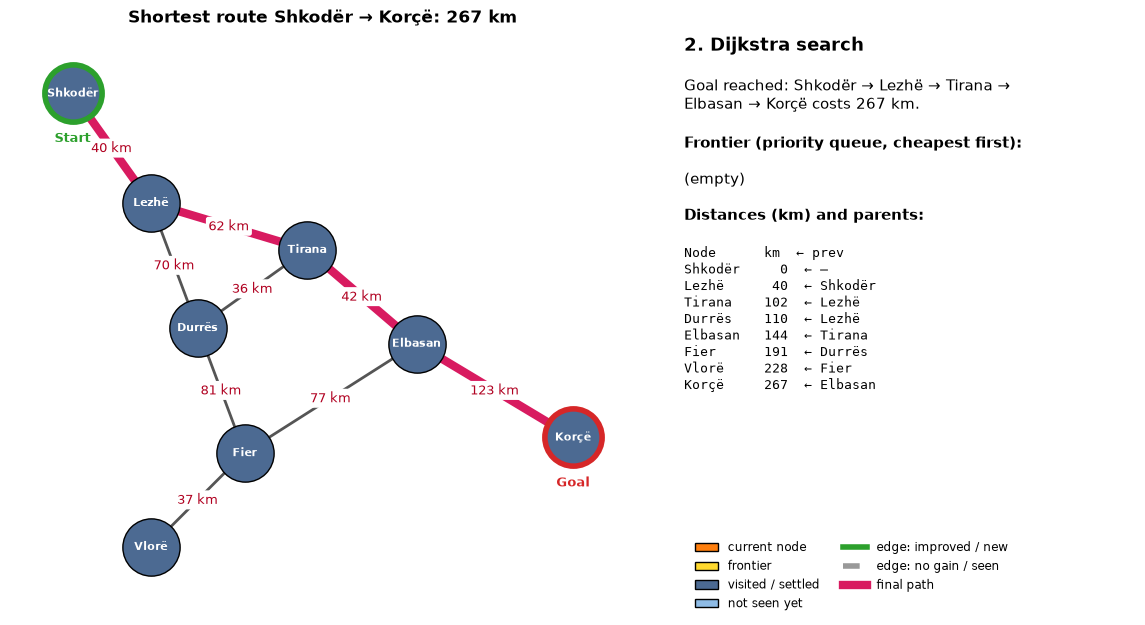

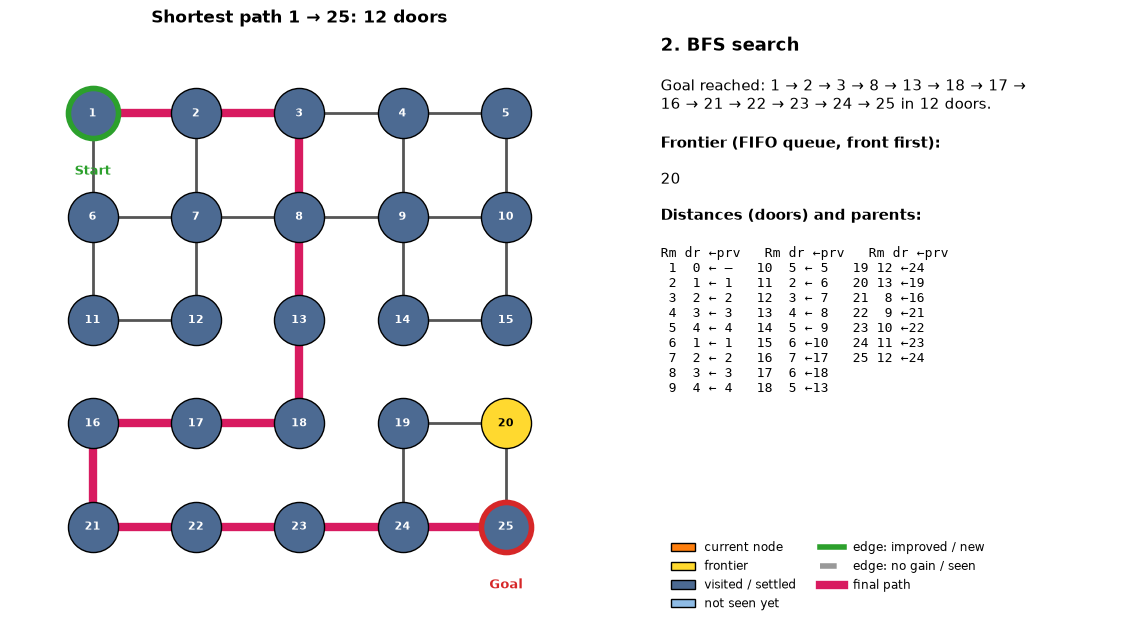

In [22]:
def city_scene(start="Shkodër", goal="Korçë"):
    return Scene(cities, True, CITY_POS, start, goal, "Cities", "Dijkstra", "km")

def maze_scene(start=1, goal=25):
    return Scene(maze.adjacency, False,
                 {room: maze_position(room, grid_width(maze.rooms)) for room in maze.adjacency},
                 start, goal, "Maze", "BFS", "doors", node_size=1300)

def inline_result(scene):
    fig, ax, panel = make_figure(scene)
    render_frame(ax, panel, scene, build_frames(scene)[-1])
    display(fig)
    plt.close(fig)

def inline_animation(scene):
    fig, animation = make_animation(scene, fps=4)
    display(HTML(animation.to_jshtml()))
    plt.close(fig)

inline_result(city_scene())
inline_result(maze_scene())

## Ndërfaqja e notebook-ut / Notebook interface

Këto kontrolle zëvendësojnë TUI, MCP dhe viewer-in web: rruga më e shkurtër, cilësia, fqinjët, të dhënat, gjurma dhe animacioni brenda Jupyter.

In [23]:
problem = widgets.Dropdown(options=["Cities", "Maze"], description="Problem")
origin = widgets.Dropdown(options=sorted(cities), value="Shkodër", description="From")
destination = widgets.Dropdown(options=sorted(cities), value="Korçë", description="To")
room_from = widgets.BoundedIntText(value=1, min=1, max=maze.rooms, description="From room")
room_to = widgets.BoundedIntText(value=25, min=1, max=maze.rooms, description="To room")
action = widgets.Dropdown(options=["Route", "Quality", "Trace", "Neighbours", "Data", "Animate"], description="Action")
run = widgets.Button(description="Run")
output = widgets.Output()

def show_selection(_):
    with output:
        output.clear_output(wait=True)
        weighted = problem.value == "Cities"
        a, b = (origin.value, destination.value) if weighted else (room_from.value, room_to.value)
        graph = city_search if weighted else maze_search
        scene = city_scene(a, b) if weighted else maze_scene(a, b)
        if action.value == "Quality":
            display(best_quality_route(cities, qualities, a, b) if weighted else {"doors": "equal cost"})
        elif action.value == "Trace":
            display(pd.DataFrame(list(graph.search_steps(a, b)))[["type", "message"]])
        elif action.value == "Neighbours":
            display(graph.adjacency[a])
        elif action.value == "Data":
            display(pd.read_csv(StringIO(CITIES_CSV if weighted else DOORS_CSV)))
        elif action.value == "Animate":
            inline_animation(scene)
        else:
            print(graph.shortest_path(a, b))
            inline_result(scene)

run.on_click(show_selection)
display(widgets.VBox([problem, origin, destination, room_from, room_to, action, run, output]))

## Verifikimi / Checks

Rezultatet reale, rastet kufi, CSV-të e pavlefshme dhe përputhja e gjurmëve me figurat kontrollohen këtu.

In [24]:
assert (len(cities), len(edge_list(cities)), maze.rooms, len(maze.doors)) == (8, 9, 25, 31)
assert city_path == ["Shkodër", "Lezhë", "Tirana", "Elbasan", "Korçë"]
assert city_cost == 267
assert best_quality_route(cities, qualities, "Shkodër", "Korçë")["quality_cost"] == 476.1
assert maze_path == [1, 2, 3, 8, 13, 18, 17, 16, 21, 22, 23, 24, 25]
assert maze_cost == 12
assert not validate(maze.adjacency, 1, 25, 25)
assert city_search.shortest_path("Tirana", "Tirana") == (["Tirana"], 0)
assert maze_search.shortest_path(0, 25) == (None, None)
for weighted, adjacency in [(False, {"A": [], "B": []}), (True, {"A": {}, "B": {}})]:
    assert Graph(adjacency, weighted).shortest_path("A", "B") == (None, None)
for scene in (city_scene(), maze_scene()):
    events = list(Graph(scene.adjacency, scene.weighted).search_steps(scene.start, scene.goal))
    assert events[-1]["path"] == build_frames(scene)[-1]["path"]
for loader, bad in [
    (load_graph, CITIES_CSV.replace("40,good", "0,good", 1)),
    (load_graph, CITIES_CSV + "Shkodër,Lezhë,40,good\n"),
    (load_roads, CITIES_CSV.replace("good", "bad", 1)),
    (load_graph, "city_a,city_b,km\nA,B,no\n"),
]:
    try:
        loader(bad)
    except ValueError:
        pass
    else:
        raise AssertionError("Malformed dataset accepted")
try:
    load_maze(DOORS_CSV + "1,25\n")
except ValueError:
    pass
else:
    raise AssertionError("Invalid door accepted")
print("All Seminar 2 algorithm, dataset, trace and boundary checks passed.")
probe_scene = Scene({"A": {"B": 1}, "B": {"A": 1}}, True,
                    {"A": (0, 0), "B": (1, 0)}, "A", "B",
                    "Animation probe", "Dijkstra", "km", figsize=(4, 3))
probe_fig, probe_animation = make_animation(probe_scene, fps=4)
assert "<script" in probe_animation.to_jshtml()
plt.close(probe_fig)
assert city_is_symmetric(cities)
assert city_is_connected(cities)
assert maze_scene().pos == {r: maze_position(r, grid_width(maze.rooms)) for r in maze.adjacency}
original_maze = maze
maze = Maze(4, 1, 4, [(1, 2), (1, 3), (2, 4), (3, 4)],
            {1: [2, 3], 2: [1, 4], 3: [1, 4], 4: [2, 3]})
assert maze_scene(1, 4).pos[4] == (1, -1)
maze = original_maze

# Probe each notebook control branch without serializing large animations.
original_inline_animation = inline_animation
animation_calls = []
def inline_animation(scene):
    animation_calls.append(scene)

for selected_problem in problem.options:
    problem.value = selected_problem
    for selected_action in action.options:
        action.value = selected_action
        with capture_output():
            show_selection(None)
assert len(animation_calls) == 2
inline_animation = original_inline_animation
problem.value, action.value = "Cities", "Route"
print("Widget branches, animation and variable-size maze geometry passed.")

# File-backed data must resolve from either supported launch directory.
assert find_data_dir(DATA_DIR.parent) == find_data_dir(DATA_DIR.parent / "notebooks") == DATA_DIR
for invalid_config in [
    "[]",
    '{"rooms": true, "entrance": 1, "exit": 2}',
    '{"rooms": 6, "entrance": 1, "exit": 6}',
    '{"rooms": 25, "entrance": 0, "exit": 25}',
    '{"rooms": 25, "entrance": 1, "exit": 1}',
    '{"rooms": 25}',
    "{",
]:
    try:
        parse_maze_config(invalid_config)
    except ValueError:
        pass
    else:
        raise AssertionError("Malformed maze configuration accepted")


All Seminar 2 algorithm, dataset, trace and boundary checks passed.
Widget branches, animation and variable-size maze geometry passed.


## Eksperimente / Experiments

Ndrysho qytetet, dhomat ose CSV-të. Krahaso BFS me Dijkstra kur peshat ndryshojnë dhe shpjego si cilësia ndryshon funksionin e kostos. [Seminari 3](seminar3.ipynb).